# Normal and cancerous liver

CosMx liver, two datasets analysed the same way. Niche labels are predicted
in each, and the gene regulatory networks learned in each are then compared
against one another.

The two parts answer different questions. The supervised part asks whether
the pretrained representation separates the annotated niches of a tissue.
The regulatory part asks what the model attends to in each condition, and
which interactions it treats differently between them.

The label sets are not the same in the two datasets. Normal liver is
annotated by zonation, cancerous liver by tumour and interface compartments,
so the two classifiers are separate models with separate heads and their
scores are not directly comparable. What is comparable is the gene graph,
which is built over the same vocabulary in both.

## 1. Setup

In [1]:
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# --- edit these -------------------------------------------------------
FOUNDATION_CKPT = "/DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt"

VOCAB_PATH      = "/DATA1/Roxana/Hierarchy/Two_levels/default_gene_vocab.json"

DATASETS = {
    "normal": {
        "data_root": "/DATA1/Roxana/Hierarchy/Two_levels/fine_tune/Liver_cosmax_normal",
        "h5ad":      "/DATA1/Roxana/Data/Normal_liver_cosmax.h5ad",
        "output":    "./results/liver_normal",
    },
    "cancer": {
        "data_root": "/DATA1/Roxana/Hierarchy/Two_levels/fine_tune/Liver_cosmax_cancer",
        "h5ad":      "/DATA1/Roxana/Data/cancer_liver_cosmax.h5ad",
        "output":    "./results/liver_cancer",
    },
}
# ----------------------------------------------------------------------

TARGET_KEY  = "y_niche"
SPLIT_COL   = "split"
FOV_COL     = "fov"
SPOT_SIZE   = 0.01
DEVICE      = "cuda:0"
BATCH_SIZE  = 512
NUM_WORKERS = 4
SEED        = 42

device = torch.device(DEVICE if torch.cuda.is_available() else "cpu")
for cfg in DATASETS.values():
    os.makedirs(cfg["output"], exist_ok=True)
print("device:", device)

device: cuda:0


## 2. Building the supervised sections

Each dataset is written as two files, `train.pt` and `test.pt`, split on the
`split` column already in `obs`. The whole training set is one graph and the
whole test set another, so a section here means a split, not a tissue run.

Both label columns are encoded and saved, so switching between `y_niche` and
`y_class` needs no rebuild. The name-to-integer mapping is written once per
dataset as `label_mappings.json`.

Run this once per dataset.

In [2]:
from pathlib import Path
import scanpy as sc

from hebi.data.graph import build_spatial_graph
from hebi.data.coarsening import create_metis_partition
from hebi.data.vocabulary import harmonise_adata

BUILD_SECTIONS = False        # set True the first time

LABEL_COL_CLASS = "cell_type"
LABEL_COL_NICHE = "niche_type"
SPLIT_COL       = "split"
K_NEIGHBORS     = 10

if BUILD_SECTIONS:
    for name, cfg in DATASETS.items():
        root = Path(cfg["data_root"])
        (root / "train").mkdir(parents=True, exist_ok=True)
        (root / "test").mkdir(parents=True, exist_ok=True)

        ad_full = sc.read_h5ad(cfg["h5ad"])
        ad_full = harmonise_adata(ad_full, VOCAB_PATH,
                                  species="human")
        sc.pp.normalize_total(ad_full, target_sum=1e4)
        sc.pp.log1p(ad_full)

        class_to_id = {l: i for i, l in
                       enumerate(sorted(ad_full.obs[LABEL_COL_CLASS].unique().astype(str)))}
        niche_to_id = {l: i for i, l in
                       enumerate(sorted(ad_full.obs[LABEL_COL_NICHE].unique().astype(str)))}
        with open(root / "label_mappings.json", "w") as f:
            json.dump({"class_mapping": class_to_id, "niche_mapping": niche_to_id},
                      f, indent=4)
        print(f"{name}: {len(class_to_id)} classes, {len(niche_to_id)} niches")

        for split in ad_full.obs[SPLIT_COL].unique().tolist():
            d = ad_full[ad_full.obs[SPLIT_COL] == split].copy()

            X = d.X.toarray() if hasattr(d.X, "toarray") else np.asarray(d.X)
            X = torch.tensor(X, dtype=torch.float32)
            coords = torch.tensor(
                d.obsm["spatial"] if "spatial" in d.obsm else d.obsm["spatial_3d"][:, :2],
                dtype=torch.float32,
            )

            edge_index, edge_attr, _ = build_spatial_graph(coords.numpy(),
                                                           k=K_NEIGHBORS)
            n_clusters = 1024 if d.n_obs >= 1024 else max(1, d.n_obs // 10)
            node2comm, super_sp = create_metis_partition(
                edge_index, X.shape[0], n_clusters, seed=SEED
            )

            torch.save({
                "X": X.half(),
                "coords": coords,
                "edge_index": edge_index,
                "node2comm": node2comm,
                "super_sp": super_sp,
                "gene_ids": torch.tensor(d.var["gene_id"].values, dtype=torch.long),
                "y_class": torch.tensor(
                    [class_to_id[l] for l in d.obs[LABEL_COL_CLASS].astype(str)],
                    dtype=torch.long),
                "y_niche": torch.tensor(
                    [niche_to_id[l] for l in d.obs[LABEL_COL_NICHE].astype(str)],
                    dtype=torch.long),
                "meta": {"species": "Human", "tissue": "Liver", "condition": name,
                         "k_neighbors": K_NEIGHBORS},
            }, root / split / f"{split}.pt")
            print(f"   {split}: {d.n_obs:,} cells")
            del d

        del ad_full

/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
for name, cfg in DATASETS.items():
    with open(os.path.join(cfg["data_root"], "label_mappings.json")) as f:
        mappings = json.load(f)

    key = "class_mapping" if TARGET_KEY == "y_class" else "niche_mapping"
    label_to_id = mappings[key]
    cfg["label_names"] = [
        k for k, _ in sorted(label_to_id.items(), key=lambda kv: kv[1])
    ]
    cfg["n_classes"] = len(cfg["label_names"])

    print(f"{name}: {cfg['n_classes']} classes")
    for i, label in enumerate(cfg["label_names"]):
        print(f"   {i:>2}  {label}")
    print()

normal: 6 classes
    0  Zone_1a/PV
    1  Zone_1b
    2  Zone_2a
    3  Zone_2b
    4  Zone_3a
    5  Zone_3b/CV

cancer: 4 classes
    0  interface
    1  non-malignant
    2  tumor
    3  tumor subtype



## 4. Training

Two independent runs of the same procedure: linear probing with the backbone
frozen, then fine-tuning at a much lower backbone learning rate. Selection is
on macro-F1, so a small niche counts as much as a large one.

In [4]:
from hebi.training.finetune.train_classifier import train_classifier

for name, cfg in DATASETS.items():
    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    cfg["history"] = train_classifier(
        foundation_ckpt=FOUNDATION_CKPT,
        data_root=cfg["data_root"],
        output_dir=cfg["output"] + "_cell",     # new folder, old results stay untouched
        level="cell",
        target_key=TARGET_KEY,

        n_epochs_linear=5,
        lr_linear=1e-3,

        do_finetune=True,
        n_epochs_finetune=5,
        lr_finetune=1e-5,

        batch_size=BATCH_SIZE,
        device=DEVICE,
        num_workers=NUM_WORKERS,
        seed=SEED,
    )


normal
Task: y_niche (6 classes) | level: cell | niche prototypes: 20
📥 Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
❄️ Backbone frozen
📁 Found 1 slides for split 'train'
📁 Found 1 slides for split 'test'

Phase 1: linear probing (5 epochs)


P1 1/5: 100%|███████████████| 1/1 [00:23<00:00, 23.77s/it, acc=0.435, loss=1.14]


  P1 ep 1 | train acc=0.4345  macroF1=0.4063  microF1=0.4345
           | test  acc=0.4946  macroF1=0.4909  microF1=0.4946
           | saved (macroF1 0.4909)


P1 2/5: 100%|███████████████| 1/1 [00:24<00:00, 24.36s/it, acc=0.466, loss=1.06]


  P1 ep 2 | train acc=0.4661  macroF1=0.4714  microF1=0.4661
           | test  acc=0.4986  macroF1=0.4692  microF1=0.4986


P1 3/5: 100%|███████████████| 1/1 [00:23<00:00, 23.80s/it, acc=0.468, loss=1.06]


... (31 outputs left out)

P2 4/5: 100%|██████████████| 1/1 [00:33<00:00, 33.10s/it, acc=0.902, loss=0.236]


  P2 ep 4 | train acc=0.9019  macroF1=0.8479  microF1=0.9019
           | test  acc=0.8911  macroF1=0.8401  microF1=0.8911
           | saved (macroF1 0.8401)


P2 5/5: 100%|███████████████| 1/1 [00:34<00:00, 34.12s/it, acc=0.905, loss=0.23]


  P2 ep 5 | train acc=0.9046  macroF1=0.8531  microF1=0.9046
           | test  acc=0.8947  macroF1=0.8459  microF1=0.8947
           | saved (macroF1 0.8459)

Best macro-F1: 0.8459
Outputs in ./results/liver_cancer_cell


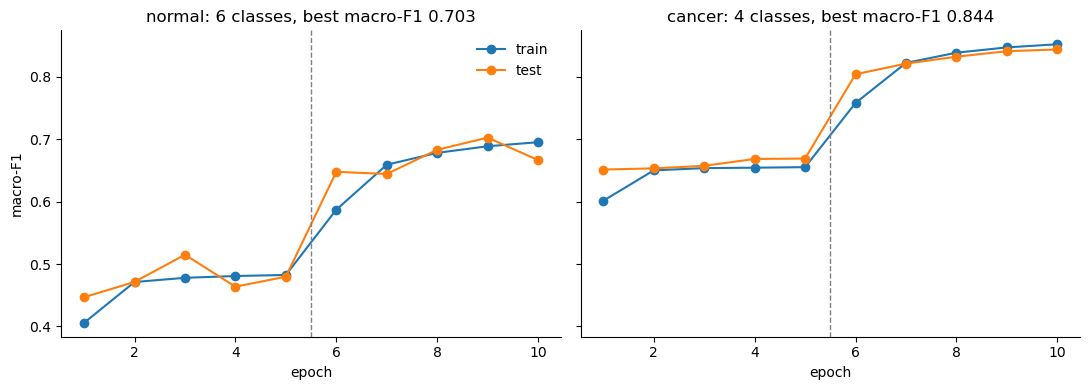

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, (name, cfg) in zip(axes, DATASETS.items()):
    h = cfg["history"]
    x = np.arange(1, len(h) + 1)
    ax.plot(x, [e["train"]["macro_f1"] for e in h], "o-", label="train")
    ax.plot(x, [e["test"]["macro_f1"] for e in h], "o-", label="test")

    phases = [e["phase"] for e in h]
    if 2 in phases:
        ax.axvline(phases.index(2) + 0.5, color="grey", ls="--", lw=1)

    best = max(h, key=lambda e: e["test"]["macro_f1"])["test"]
    ax.set_title(f"{name}: {cfg['n_classes']} classes, "
                 f"best macro-F1 {best['macro_f1']:.3f}")
    ax.set_xlabel("epoch")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("macro-F1")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

The two numbers describe different problems and should not be read as one
being the better dataset. Six zonation labels form a gradient with no sharp
boundaries, so neighbouring zones are expected to be confused. Four tumour
compartments are more distinct but more unevenly sized. The confusion
matrices below say more than either score.

## 5. Predicting whole sections

`iterate_supervised_batches` yields labels but not the seed node indices, so
predictions come back in sampler order and cannot be matched to cells. The
function below repeats the same unpacking and keeps the indices, writing each
prediction into an array in the section's own cell order.

In [9]:
from hebi.training.finetune.finetuner import HebiClassifier
from hebi.training.finetune.loader import (
    get_slide_list, load_supervised_slide_dict, build_local_sampler,
)


def load_trained_model(checkpoint_path, n_classes, foundation_ckpt, device,
                       level="cell"):
    ckpt = torch.load(foundation_ckpt, map_location="cpu")
    k2 = ckpt["pooler_lvl2"]["l2_prototypes"].shape[0]
    del ckpt

    model = HebiClassifier(n_classes=n_classes, level=level,
                           num_prototypes_lvl2=k2).to(device)
    model.load_pretrained_weights(foundation_ckpt, device, freeze_backbone=False)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()
    return model


@torch.no_grad()
def predict_section(model, pt_path, target_key, device,
                    batch_size=512, num_workers=4):
    """Predict every cell in one section, in the section's own cell order."""
    slide   = load_supervised_slide_dict(pt_path, target_key=target_key)
    sampler = build_local_sampler(slide, batch_size=batch_size,
                                  shuffle=False, num_workers=num_workers)

    X         = slide["X"].float().to(device)
    node2comm = slide["node2comm"].long().to(device)
    super_sp  = slide["super_sp"].float().to(device)
    gene_ids  = slide["gene_ids"].long().to(device)
    true      = slide[target_key].long().cpu().numpy()

    global_reps = None
    if model.level == "niche":
        global_reps = model.section_global_reps(
            slide, device, batch_size=batch_size, num_workers=num_workers)

    pred = np.full(X.shape[0], -1, dtype=np.int64)
    for edge_block, node_idx_b, bs in sampler:
        node_idx_b = node_idx_b.to(device)
        seed = node_idx_b[:bs]
        logits = model(
            x_subgraph_raw=X[node_idx_b],
            edge_index_subgraph=edge_block[:2].to(device),
            edge_attr_b=(edge_block[2].to(device), edge_block[3].to(device)),
            node2comm_batch=node2comm[seed],
            super_sp_global=super_sp,
            gene_ids=gene_ids,
            device=device,
            bs=bs,
            global_reps=global_reps,
        )
        pred[seed.cpu().numpy()] = logits.argmax(dim=1).cpu().numpy()

    unseen = int((pred < 0).sum())
    if unseen:
        print(f"  {unseen} cells never appeared as a seed node")
    return pred, true

📁 Found 1 slides for split 'test'
📥 Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
🔥 Backbone trainable
normal fov 172 (test) probe: acc 0.487
📥 Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
🔥 Backbone trainable
normal fov 172 (test) finetuned: acc 0.503


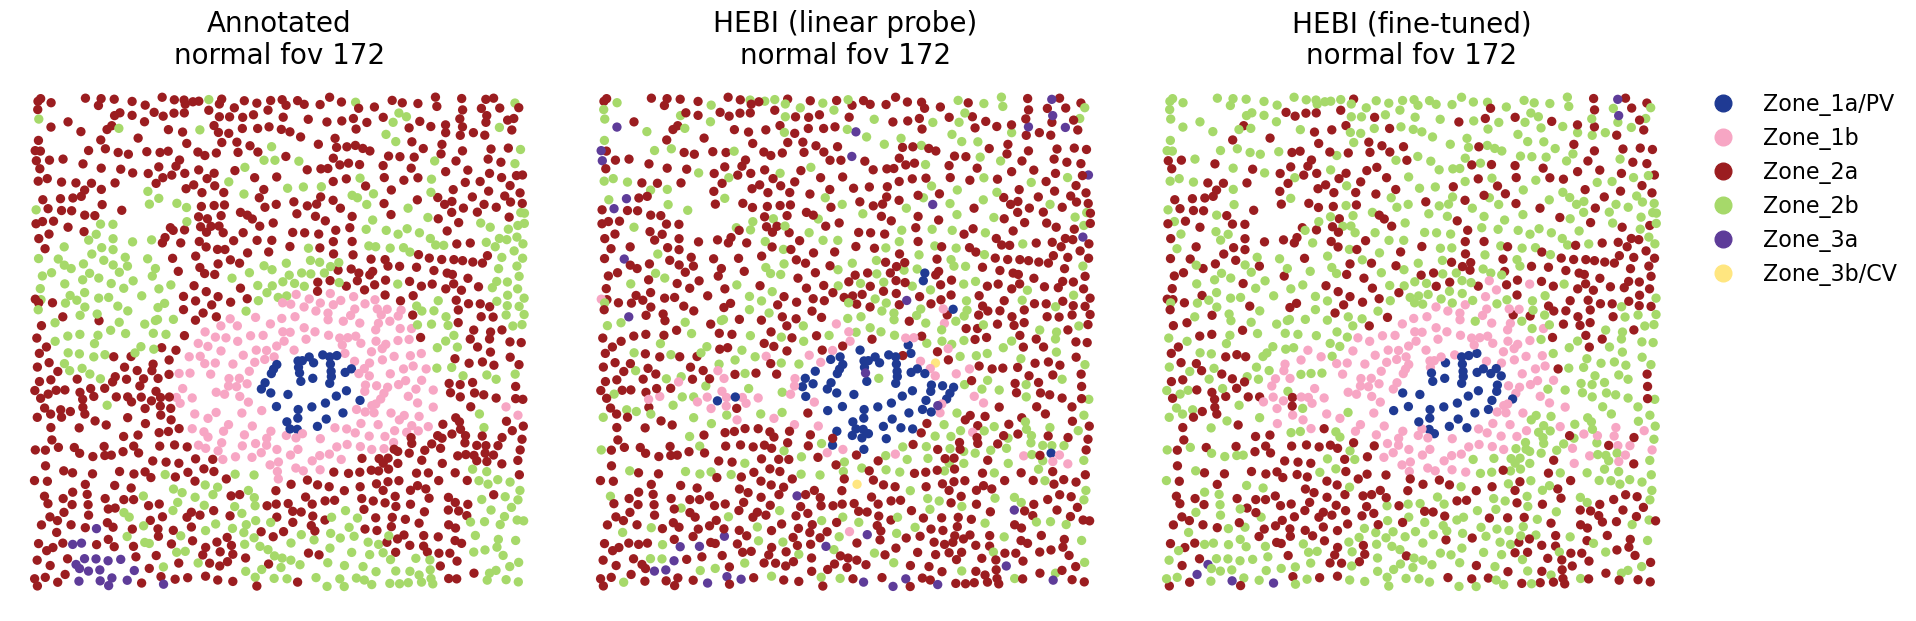

📁 Found 1 slides for split 'test'
📥 Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
🔥 Backbone trainable
cancer fov 353 (test) probe: acc 0.640
📥 Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
🔥 Backbone trainable
cancer fov 353 (test) finetuned: acc 0.830


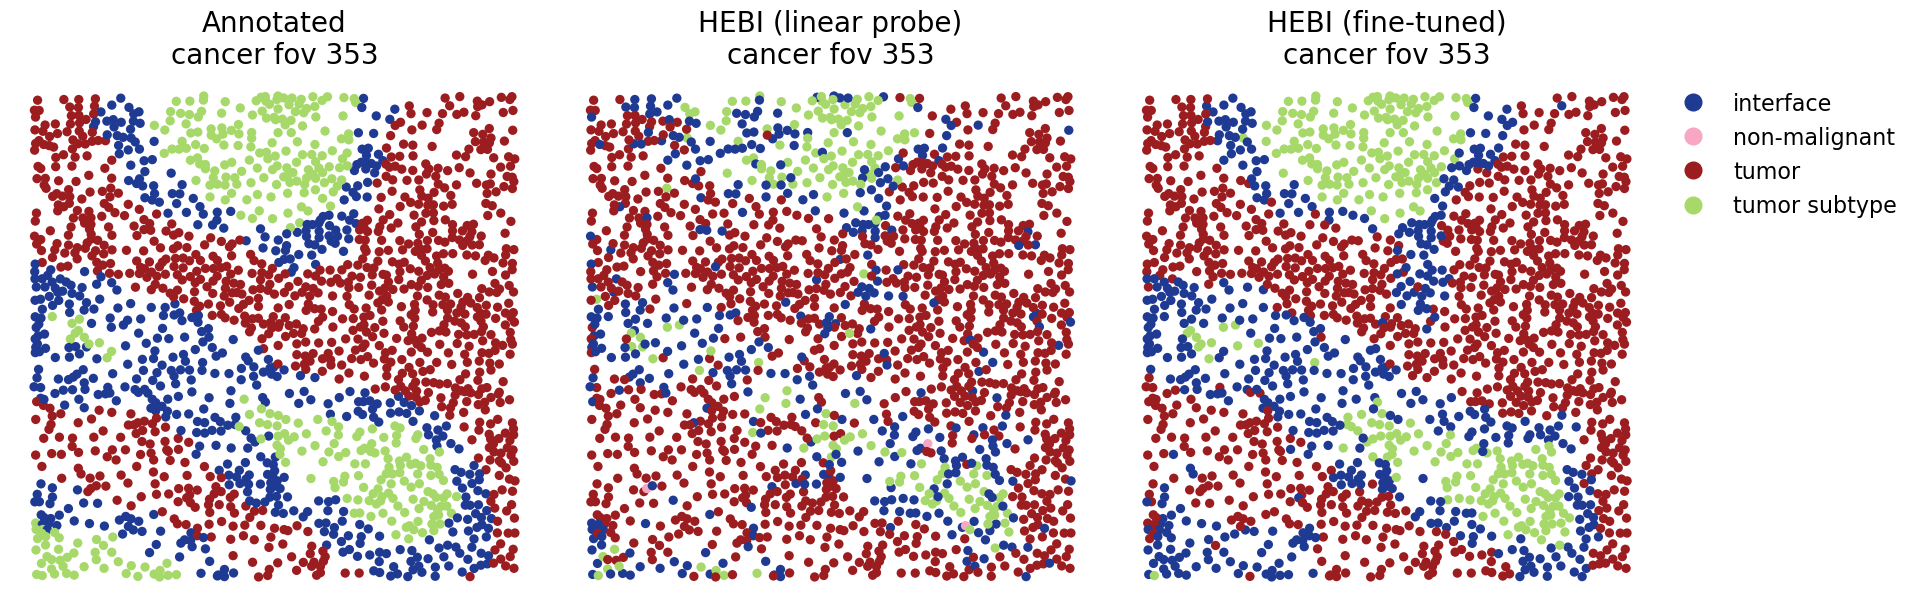

In [25]:
import scanpy as sc
from hebi.training.finetune.loader import get_slide_list

FOVS = {"normal": 172, "cancer": 353}
from matplotlib.colors import ListedColormap

from matplotlib.colors import ListedColormap

VIBRANT = ["#1F3A93",  # dark blue
           "#F7A6C4",  # light orange
           "#9B1D20",  # dark red
           "#A6D96A",  # light green
           "#5E3C99",  # dark purple
           "#FFE680",  # light yellow
           "#7F4F24",  # dark brown
           "#F7A6C4",  # light pink
           "#0B7A75",  # dark teal
           "#D9D9D9"]  # light grey

LABEL_COLORS = ListedColormap(VIBRANT)
POINT_SIZE = 45

LEVEL = "cell"
def fov_cells(name, fov):
    """Which split holds this FOV, and a boolean mask over that split's cells
    in .pt order (the .pt was written from adata[split] in obs order)."""
    cfg = DATASETS[name]
    if "_obs" not in cfg:
        cfg["_obs"] = sc.read_h5ad(cfg["h5ad"], backed="r").obs[[SPLIT_COL, FOV_COL]].copy()
    obs = cfg["_obs"]
    hit = obs[obs[FOV_COL].astype(str) == str(fov)]
    if hit.empty:
        raise ValueError(f"{name}: fov {fov} not found")
    splits = hit[SPLIT_COL].astype(str).unique()
    assert len(splits) == 1, f"fov {fov} spans splits {splits}"
    split = splits[0]
    sub = obs[obs[SPLIT_COL].astype(str) == split]
    return split, (sub[FOV_COL].astype(str) == str(fov)).to_numpy()


def _colors(labels):
    return [LABEL_COLORS(int(k) % 10) if k >= 0 else (0.8, 0.8, 0.8, 1.0) for k in labels]


def plot_fov_predictions(name):
    cfg, fov = DATASETS[name], FOVS[name]
    backbone = cfg.get("backbone_ckpt", FOUNDATION_CKPT)
    split, mask = fov_cells(name, fov)
    pt = get_slide_list(cfg["data_root"], split=split)[0]
    xy = torch.load(pt, map_location="cpu")["coords"].numpy()[mask]

    panels = []
    for tag, title in [("probe", "HEBI (linear probe)"), ("finetuned", "HEBI (fine-tuned)")]:
        ckpt = os.path.join(cfg["output"] + "_cell", f"best_{tag}_model.pt")
        if not os.path.exists(ckpt):
            print(f"{name}: no {os.path.basename(ckpt)}, skipped")
            continue
        model = load_trained_model(ckpt, cfg["n_classes"], backbone, device, level=LEVEL)
        pred, true = predict_section(model, pt, TARGET_KEY, device,
                                     batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
        del model; torch.cuda.empty_cache()
        assert len(mask) == len(true), "AnnData split and .pt cell counts differ"
        pred, true = pred[mask], true[mask]
        print(f"{name} fov {fov} ({split}) {tag}: acc {np.mean(pred == true):.3f}")
        panels.append((title, pred))

    names = cfg["label_names"]
    handles = [plt.Line2D([], [], marker="o", ls="", color=LABEL_COLORS(i % 10), label=l)
               for i, l in enumerate(names)]

    fig, axes = plt.subplots(1, 1 + len(panels), figsize=(6.5 * (1 + len(panels)), 6.5))
    plt.rcParams.update({"font.size": 18, "axes.titlesize": 20, "legend.fontsize": 16})
    axes = np.atleast_1d(axes)
    for ax, (title, lab) in zip(axes, [("Annotated", true)] + panels):
        ax.scatter(xy[:, 0], xy[:, 1], s=POINT_SIZE, c=_colors(lab), linewidths=0)
        ax.set_title(f"{title}\n{name} fov {fov}")
        ax.set_aspect("equal"); ax.axis("off")
        axes[-1].legend(handles=handles, frameon=False, markerscale=2,
                    loc="upper left", bbox_to_anchor=(1.0, 1.0))
    plt.tight_layout()
    out = os.path.join(cfg["output"] + "_cell", f"fov{fov}_predictions")
    for ext in ("svg", "png"):
        plt.savefig(f"{out}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()


for name in DATASETS:
    plot_fov_predictions(name)

In [12]:
for name, cfg in DATASETS.items():
    ckpt = os.path.join(cfg["output"], "best_finetuned_model.pt")
    if not os.path.exists(ckpt):
        ckpt = os.path.join(cfg["output"], "best_probe_model.pt")

    model = load_trained_model(ckpt, cfg["n_classes"], FOUNDATION_CKPT, device)
    cfg["per_section"] = {}

    print(f"\n{name} ({os.path.basename(ckpt)})")
    for pt_path in get_slide_list(cfg["data_root"], split="test"):
        section = os.path.basename(pt_path).replace(".pt", "")
        pred, true = predict_section(model, pt_path, TARGET_KEY, device,
                                     batch_size=BATCH_SIZE,
                                     num_workers=NUM_WORKERS)
        cfg["per_section"][section] = {"pred": pred, "true": true}
        acc = float((pred == true)[pred >= 0].mean())
        print(f"  {section:<30} {len(pred):>7,} cells   acc {acc:.4f}")

    del model
    torch.cuda.empty_cache()

📥 Loading checkpoint: /DATA1/Roxana/Hierarchy/Two_levels/hebi_foundation_best_new.pt

normal (best_finetuned_model.pt)
📁 Found 1 slides for split 'test'
  test                            29,458 cells   acc 0.5878
📥 Loading checkpoint: /DATA1/Roxana/Hierarchy/Two_levels/hebi_foundation_best_new.pt

cancer (best_finetuned_model.pt)
📁 Found 1 slides for split 'test'
  test                            49,563 cells   acc 0.8942


## 6. Confusion matrices

Computed on integer class ids. Passing the label names to `labels=` while the
predictions are integers gives an all-zero matrix without raising anything,
so names are used only for the tick labels.

Rows are normalised, so the diagonal is per-class recall and the off-diagonal
mass says where the errors go. In normal liver, confusion concentrated
between adjacent zones is the expected failure of a gradient; confusion
between `Zone_1a/PV` and `Zone_3b/CV`, the two ends, would not be.

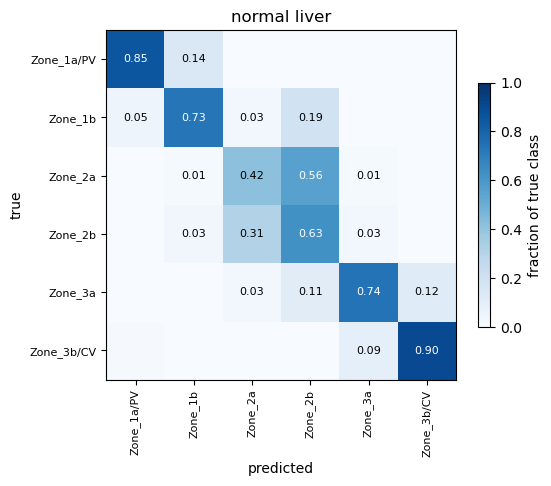

              precision    recall  f1-score   support

  Zone_1a/PV       0.92      0.85      0.88      1476
     Zone_1b       0.67      0.73      0.70      2126
     Zone_2a       0.52      0.42      0.46     10479
     Zone_2b       0.55      0.63      0.59     12567
     Zone_3a       0.68      0.74      0.71      1726
  Zone_3b/CV       0.82      0.90      0.86      1084

    accuracy                           0.59     29458
   macro avg       0.69      0.71      0.70     29458
weighted avg       0.58      0.59      0.58     29458



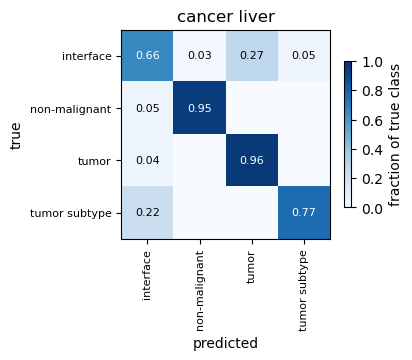

               precision    recall  f1-score   support

    interface       0.66      0.66      0.66      7736
non-malignant       0.92      0.95      0.94      2993
        tumor       0.94      0.96      0.95     34625
tumor subtype       0.90      0.77      0.83      4209

     accuracy                           0.89     49563
    macro avg       0.86      0.83      0.84     49563
 weighted avg       0.89      0.89      0.89     49563



In [13]:
from sklearn.metrics import confusion_matrix, classification_report

for name, cfg in DATASETS.items():
    K = cfg["n_classes"]
    y_true = np.concatenate([d["true"][d["pred"] >= 0]
                             for d in cfg["per_section"].values()])
    y_pred = np.concatenate([d["pred"][d["pred"] >= 0]
                             for d in cfg["per_section"].values()])

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(K))
    cm_norm = cm / (cm.sum(axis=1, keepdims=True) + 1e-12)

    fig, ax = plt.subplots(figsize=(1.5 + 0.7 * K, 1.2 + 0.6 * K))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    fig.colorbar(im, ax=ax, shrink=0.7, label="fraction of true class")

    ax.set_xticks(np.arange(K)); ax.set_yticks(np.arange(K))
    ax.set_xticklabels(cfg["label_names"], rotation=90, fontsize=8)
    ax.set_yticklabels(cfg["label_names"], fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{name} liver")

    for i in range(K):
        for j in range(K):
            if cm_norm[i, j] > 0.01:
                ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                        fontsize=8,
                        color="white" if cm_norm[i, j] > 0.5 else "black")

    plt.tight_layout()
    plt.savefig(os.path.join(cfg["output"], "confusion_matrix.svg"))
    plt.show()

    print(classification_report(y_true, y_pred, labels=np.arange(K),
                                target_names=cfg["label_names"],
                                zero_division=0))

## 7. Predictions in space

Aggregate metrics say how often the model is right, not where it is wrong.

The test set is a single `.pt`, so the predictions cover every test cell
across all tissue runs at once. The AnnData is subset the same way, by the
`split` column, which is what puts the two in the same order. The assertion
below stops if the counts disagree rather than plotting a shifted
assignment. Set `FOV_TO_PLOT` to look at one field of view.

/tmp/ipykernel_1541028/622487509.py:30: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(sub, color=["annotated", "predicted"], spot_size=SPOT_SIZE,


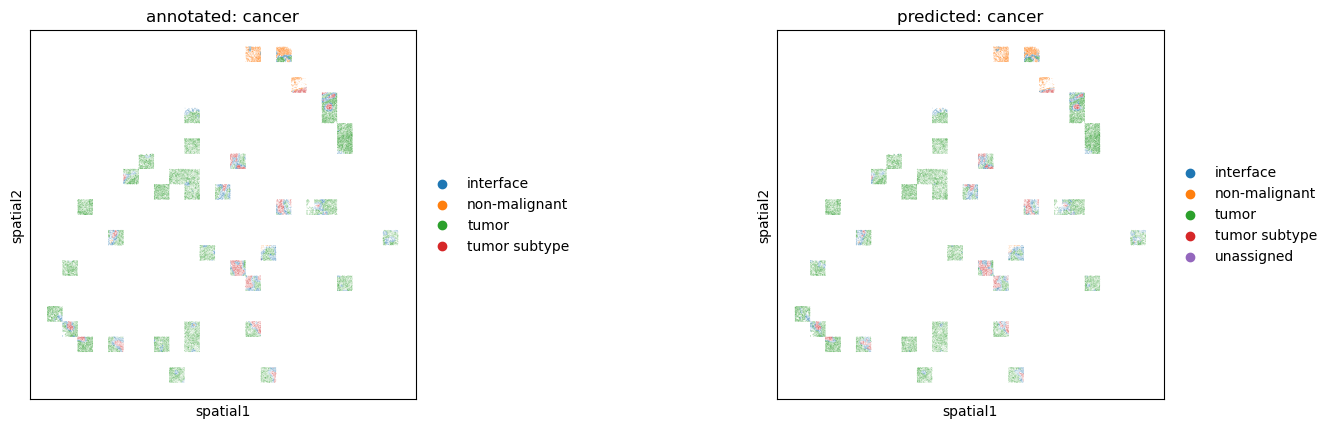

5,243 of 49,563 cells misclassified (10.6%)


In [14]:
import scanpy as sc

DATASET_TO_PLOT = "cancer"
FOV_TO_PLOT     = None        # None plots every test cell at once

cfg = DATASETS[DATASET_TO_PLOT]
section = list(cfg["per_section"])[0]        # "test"

adata = sc.read_h5ad(cfg["h5ad"])
sub = adata[adata.obs[SPLIT_COL].astype(str) == section].copy()

pred = cfg["per_section"][section]["pred"]
true = cfg["per_section"][section]["true"]
assert sub.n_obs == len(pred), (
    f"{sub.n_obs} cells in the AnnData but {len(pred)} in the section file. "
    "The .pt fixes the cell order, so these must match."
)

names = cfg["label_names"]
sub.obs["annotated"] = pd.Categorical([names[i] for i in true], categories=names)
sub.obs["predicted"] = pd.Categorical(
    [names[i] if i >= 0 else "unassigned" for i in pred],
    categories=names + ["unassigned"],
)

if FOV_TO_PLOT is not None:
    sub = sub[sub.obs[FOV_COL].astype(str) == str(FOV_TO_PLOT)].copy()

label = f"{DATASET_TO_PLOT}" + (f" fov {FOV_TO_PLOT}" if FOV_TO_PLOT else "")
sc.pl.spatial(sub, color=["annotated", "predicted"], spot_size=SPOT_SIZE,
              title=[f"annotated: {label}", f"predicted: {label}"],
              wspace=0.3, show=True)

mismatch = (sub.obs["annotated"].astype(str) != sub.obs["predicted"].astype(str))
print(f"{mismatch.sum():,} of {sub.n_obs:,} cells misclassified "
      f"({mismatch.mean():.1%})")

## 8. Gene regulatory networks in each condition

The regulatory analysis does not come from the supervised model. The
classifier never builds a gene graph: `grn_layer` and `gene_graphs` stay
unset in `HebiCellTypeClassifier`, so no attention is produced on that path.
The edge tables below come from the unsupervised pipeline, run separately on
each dataset.

Two things make the comparison interpretable. Both runs must use
`mode="continual"` with `grn=True`, since the refinement layer is only
trained during adaptation and zero-shot attention carries no learned signal.
And both must use the same gene vocabulary, which is what puts the two edge
tables in a shared namespace.

Set `RUN_GRN = True` to produce the tables; skip it if they already exist.

In [15]:
RUN_GRN = True

from pathlib import Path
import glob

# Fresh directory. The old grn_reports tables came from the run where the
# refinement layer was trained without input masking, so its attention was
# uniform and nothing derived from it is usable.
GRN_ROOT = Path("./results/liver_grn")
K_GRN    = 30          # unsupervised pipeline default, not the k=5 used above

if RUN_GRN:
    from hebi.data.preprocess import preprocess_h5ad
    from hebi.inference.pipeline import (
        encode_sections, cluster_sections, analyse_grn,
    )

    for name, cfg in DATASETS.items():
        proc_dir = GRN_ROOT / name / "processed"
        out_dir  = GRN_ROOT / name / "results"
        proc_dir.mkdir(parents=True, exist_ok=True)

        produced = preprocess_h5ad(
            h5ad_path=cfg["h5ad"],
            out_root=proc_dir,
            vocab_path=VOCAB_PATH,
            task="clustering",
            k=K_GRN,
            species="Human",
            counts_layer=None,
            overwrite=False,
        )
        section_files = [p.name for p in produced]

        sections_i, ctx_i = encode_sections(
            checkpoint_path=FOUNDATION_CKPT,
            data_dir=str(proc_dir),
            section_files=section_files,
            h5ad_files=[cfg["h5ad"]],
            vocab_path=VOCAB_PATH,
            section_labels=[name],

            mode="continual",
            init="pretrained",
            num_epochs=10,
            lr=1e-4,

            grn=True,
            species="Human",

            output_dir=str(out_dir),
            seed=SEED,
        )

        written_i = cluster_sections(
            sections_i, ctx_i,
            n_cell_clusters=cfg["n_classes"],
            n_composition_niches=cfg["n_classes"],
            composition_neighbors=200,
            point_size=2,
        )
        analyse_grn(
            sections_i, ctx_i,
            cluster_key=written_i["composition_niches"],
            top_k_edges=5, run_report=True, run_ccc=False,
        )

        del sections_i, ctx_i
        torch.cuda.empty_cache()

# Resolve the edge tables from what the run actually wrote, so the paths
# cannot drift from the tables being compared.



Loading Normal_liver_cosmax.h5ad
  metadata: {'species': 'Unknown', 'tissue': 'Liver', 'disease': 'Normal'}
Covered genes: 999/1000 (99.90%)
  [Normal_liver_cosmax] data status: raw_counts
           all values integral, max 778 — raw counts
           applied: log1p
           library size NOT corrected. Pass --normalise to apply normalize_total before log1p.
  332,877 cells; querying 20,000 of them up to k=75
  [Normal_liver_cosmax] k=30 spans 2.14 cell diameters (median nearest-neighbour distance 0.01)
🔧 Building 30-NN spatial graph (coords=(332877, 2)) ...
✅ Graph built: 332877 nodes, 10609872 edges
🔧 [METIS] Creating NetworkX graph for 332877 nodes...
🔧 [METIS] Running METIS partitioning to create 1024 partitions...
✅ [METIS] METIS partitioning complete.
🔧 [METIS] Computing super-graph adjacency...
🔧 [METIS] Computing super-graph shortest paths...
✅ [METIS] Fixed partition and distance matrix created.
  saved Normal_liver_cosmax.pt  (332877 cells, 10609872 edges, whole slide)
See

Encoding results/liver_grn/normal/processed/Normal_liver_cosmax.pt: 100%|█| 163/


  332,877 cells encoded; 20/20 prototypes in use

Cell-level clustering: kmeans, k=6  ->  obs['z0_kmeans_6']
Niche-level clustering: 6 niches from 200-neighbour composition  ->  obs['comp_niches_6']

normal
  z0_kmeans_6            FIDE=0.3571
  prototypes             FIDE=0.2206
  comp_niches_6          FIDE=0.8706

  Saved z0_kmeans_6 (s=2.0)
  Saved comp_niches_6 (s=2.0)

GRN analysis, grouped by 'comp_niches_6'
  dropped 5021 reverse copies (5849 interactions remain)
  7 interactions across 6 groups -> results/liver_grn/normal/results/grn_top5_normal

  GRN report -> results/liver_grn/normal/results/Normal_liver_cosmax_plot/grn

GLOBAL PRE-CLUSTERING GRN REPORT

[1] Top edges by attention
source_gene target_gene  attention     edge_types  curated
       FZD3      WNT10B   0.763800        pathway     True
       CD48         CD2   0.880360         ligrec     True
       FZD3       WNT9A   0.740993        pathway     True
      BIRC5        TCF7   0.647400        pathway     True
   

Encoding results/liver_grn/cancer/processed/cancer_liver_cosmax.pt: 100%|█| 225/


  460,441 cells encoded; 20/20 prototypes in use

Cell-level clustering: kmeans, k=4  ->  obs['z0_kmeans_4']
Niche-level clustering: 4 niches from 200-neighbour composition  ->  obs['comp_niches_4']

cancer
  z0_kmeans_4            FIDE=0.4620
  prototypes             FIDE=0.2023
  comp_niches_4          FIDE=0.9322

  Saved z0_kmeans_4 (s=2.0)
  Saved comp_niches_4 (s=2.0)

GRN analysis, grouped by 'comp_niches_4'
  dropped 5021 reverse copies (5817 interactions remain)
  9 interactions across 4 groups -> results/liver_grn/cancer/results/grn_top5_cancer

  GRN report -> results/liver_grn/cancer/results/cancer_liver_cosmax_plot/grn

GLOBAL PRE-CLUSTERING GRN REPORT

[1] Top edges by attention
source_gene target_gene  attention     edge_types  curated
       FZD3      WNT10B   0.725688        pathway     True
       CD48         CD2   0.809380         ligrec     True
       FZD3       WNT9A   0.676096        pathway     True
       FZD3       RNF43   0.778297        pathway     True
   

FileNotFoundError: normal: expected one edge table, found 0. Run with RUN_GRN = True first.

In [31]:
GRN_CSV = {}
for name in DATASETS:
    hits = glob.glob(str(GRN_ROOT / name / "results" / "*_plot" / "grn" /
                         "*_edges_ranked_competitive.csv"))
    if len(hits) == 1:
        GRN_CSV[name] = hits[0]
        print(f"{name}: {os.path.relpath(hits[0])}")
    else:
        print(f"{name}: {len(hits)} tables found, not resolved")

missing = [n for n in DATASETS if n not in GRN_CSV]
if missing:
    print(f"\nstill to run: {missing}")

normal: results/liver_grn/normal/results/Normal_liver_cosmax_plot/grn/Normal_liver_cosmax_edges_ranked_competitive.csv
cancer: results/liver_grn/cancer/results/cancer_liver_cosmax_plot/grn/cancer_liver_cosmax_edges_ranked_competitive.csv


### Which edges exist in each condition

The gene graph is not fixed across conditions. Curated priors are the same,
but the co-expression edges are measured from the data, so each condition
gets a graph of its own. Only the shared edges can have their attention
compared; the rest are a statement about the graph, not about what the model
learned.

In [32]:
normal = pd.read_csv(GRN_CSV["normal"])
cancer = pd.read_csv(GRN_CSV["cancer"])

for df in (normal, cancer):
    df["edge"] = df["source_gene"].astype(str) + " -> " + df["target_gene"].astype(str)

n_edges, c_edges = set(normal["edge"]), set(cancer["edge"])
shared = n_edges & c_edges

print(f"edges in normal : {len(n_edges):>5}")
print(f"edges in cancer : {len(c_edges):>5}")
print(f"shared          : {len(shared):>5}  "
      f"({len(shared)/len(n_edges):.1%} of normal, "
      f"{len(shared)/len(c_edges):.1%} of cancer)")
print(f"normal only     : {len(n_edges - c_edges):>5}")
print(f"cancer only     : {len(c_edges - n_edges):>5}")

edges in normal : 10736
edges in cancer : 10705
shared          : 10686  (99.5% of normal, 99.8% of cancer)
normal only     :    50
cancer only     :    19


### Controlling for competition before comparing attention

Attention is normalised over each target gene's incoming edges, so an edge's
weight depends on how many regulators compete for that target. If a target
gains a co-expression regulator in one condition, the attention on its
existing edges drops even when nothing about them changed.

So a raw attention difference between conditions is only interpretable where
the in-degree is the same. The cell below reports how often that holds and
adds a competition-corrected value, `attention` times `target_in_degree`,
which expresses each edge relative to an even split among its competitors and
is comparable even when the in-degree differs.

In [33]:
keep_n = normal.sort_values("attention", ascending=False).drop_duplicates("edge")
keep_c = cancer.sort_values("attention", ascending=False).drop_duplicates("edge")

m = keep_n.merge(keep_c, on=["source_gene", "target_gene"], suffixes=("_n", "_c"))
m["edge"] = m["source_gene"] + " -> " + m["target_gene"]

same_deg = m["target_in_degree_n"] == m["target_in_degree_c"]
print(f"{len(m)} shared edges, {same_deg.mean():.1%} with unchanged in-degree")

for side in ("n", "c"):
    m[f"rel_{side}"] = m[f"attention_{side}"] * m[f"target_in_degree_{side}"]

m["delta"]     = m["attention_c"] - m["attention_n"]
m["delta_rel"] = m["rel_c"] - m["rel_n"]

from scipy.stats import spearmanr
print("spearman(normal, cancer) attention: %.4f" %
      spearmanr(m.attention_n, m.attention_c).statistic)
print("spearman(normal, cancer) corrected: %.4f" %
      spearmanr(m.rel_n, m.rel_c).statistic)

cols = ["edge", "attention_n", "attention_c", "delta",
        "rel_n", "rel_c", "delta_rel", "evidence_tier_n"]
print("\nLargest increase in cancer (competition-corrected):")
print(m.nlargest(10, "delta_rel")[cols].to_string(index=False))
print("\nLargest increase in normal (competition-corrected):")
print(m.nsmallest(10, "delta_rel")[cols].to_string(index=False))

10686 shared edges, 97.2% with unchanged in-degree
spearman(normal, cancer) attention: 0.9372
spearman(normal, cancer) corrected: 0.9039

Largest increase in cancer (competition-corrected):
           edge  attention_n  attention_c    delta    rel_n     rel_c  delta_rel evidence_tier_n
  ADGRL1 -> MYC     0.037622     0.113799 0.076177 4.364175 13.200667   8.836492      prior_only
 TGFBI -> TGFB1     0.036624     0.122652 0.086028 3.735654 12.510502   8.774847      prior_only
 CDKN1A -> IL1B     0.053424     0.196509 0.143084 2.617787  9.628923   7.011136      prior_only
 CDKN1A -> AKT1     0.021490     0.100393 0.078902 1.805163  8.432971   6.627808      prior_only
  HSPB1 -> TP53     0.031752     0.087135 0.055383 3.429266  9.410630   5.981364      prior_only
   CD79A -> FN1     0.014582     0.136735 0.122153 0.758263  6.700030   5.941767      prior_only
HLA-DRB1 -> FOS     0.012923     0.083232 0.070309 1.085529  6.991455   5.905926      prior_only
  CDKN1A -> JUN     0.014512     0

A high correlation between the two conditions means the model attends to
broadly the same structure in both, and the differences worth reporting are
the edges that move against that background rather than the top of either
list on its own.

In [35]:
def dumbbell(df, value_n, value_c, top_k=30, title="", save_path=None, font=10):
    d = df.reindex(df[value_c].sub(df[value_n]).abs()
                     .sort_values(ascending=False).index).head(top_k)
    d = d.iloc[::-1].reset_index(drop=True)
    y = np.arange(len(d))

    fig, ax = plt.subplots(figsize=(7, max(5, 0.28 * len(d))))
    ax.hlines(y, d[value_n], d[value_c], color="lightgray", lw=1.5, zorder=1)
    ax.scatter(d[value_n], y, s=40, color="#4A3B75", label="normal", zorder=2)
    ax.scatter(d[value_c], y, s=40, color="#B31B54", label="cancer", zorder=3)

    ax.set_yticks(y); ax.set_yticklabels(d["edge"], fontsize=font * 0.85)
    ax.tick_params(axis="x", labelsize=font)
    ax.set_xlabel("attention relative to an even split among competitors", fontsize=font)
    ax.set_title(title, fontsize=font + 1, loc="left")
    ax.set_ylim(-0.8, len(d) - 0.2)
    ax.legend(frameon=False, fontsize=font, loc="upper center",
              bbox_to_anchor=(0.5, -0.08 * 30 / max(len(d), 10)), ncol=2)   # under the x-axis label
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    if save_path:
        stem = str(save_path).rsplit(".", 1)[0]
        for ext in ("svg", "png"):
            fig.savefig(f"{stem}.{ext}", dpi=400, bbox_inches="tight")
            print("saved", f"{stem}.{ext}")
    plt.show()


dumbbell(m, "rel_n", "rel_c", top_k=30,
         title="Shared edges with the largest change between conditions",
         save_path="liver_shared_edges_change.svg")

saved liver_shared_edges_change.svg
saved liver_shared_edges_change.png


### Edges present in only one condition

These come from the co-expression component of the graph, so an edge unique
to cancer means the two genes covary there and not in normal tissue. That is
a statement about expression, not about attention, and it is worth reading
separately from the shared-edge comparison above.

In [24]:
only_normal = keep_n[~keep_n["edge"].isin(c_edges)].nlargest(25, "attention")
only_cancer = keep_c[~keep_c["edge"].isin(n_edges)].nlargest(25, "attention")

show = ["source_gene", "target_gene", "attention", "target_in_degree",
        "edge_types", "evidence_tier"]
show_n = [c for c in show if c in only_normal.columns]

print("Top edges unique to cancer:")
print(only_cancer[show_n].to_string(index=False))
print("\nTop edges unique to normal:")
print(only_normal[show_n].to_string(index=False))

Top edges unique to cancer:
source_gene target_gene  attention  target_in_degree        edge_types evidence_tier
        CD4    HLA-DPA1   0.795761                 2    pathway|ligrec    prior_only
      H2AZ1       HMGN2   0.602262                 2          spearman     data_only
       ENO1        PGK1   0.532701                 3          spearman     data_only
        MYC       HMGN2   0.397738                 2         tf_target    prior_only
       ENO1         MIF   0.356647                 5          spearman     data_only
        MIF        PGK1   0.320490                 3          spearman     data_only
      APOC1         CLU   0.314685                 6          spearman     data_only
       CD74    HLA-DPA1   0.204239                 2          spearman     data_only
      HIF1A        PGK1   0.146809                 3 pathway|tf_target    prior_only
      H2AZ1       STMN1   0.120900                 7          spearman     data_only
      HMGN2       STMN1   0.104610   

In [25]:
combined = pd.concat([
    only_normal.assign(condition="normal only"),
    only_cancer.assign(condition="cancer only"),
], ignore_index=True)

sources = sorted(combined["source_gene"].unique())
targets = sorted(combined["target_gene"].unique())
combined["x"] = combined["target_gene"].map({g: i for i, g in enumerate(targets)})
combined["y"] = combined["source_gene"].map({g: i for i, g in enumerate(sources)})

v = combined["attention"].to_numpy(float)
sizes = np.full(len(v), 120.0) if v.max() == v.min() else \
        40 + 260 * (v - v.min()) / (v.max() - v.min())

fig, ax = plt.subplots(figsize=(1 + 0.4 * len(targets), 1 + 0.35 * len(sources)))
for label, colour in [("normal only", "#4A3B75"), ("cancer only", "#B31B54")]:
    mask = (combined["condition"] == label).to_numpy()
    ax.scatter(combined.loc[mask, "x"], combined.loc[mask, "y"],
               s=sizes[mask], color=colour, alpha=0.8, label=label,
               rasterized=True)

ax.set_xticks(range(len(targets))); ax.set_xticklabels(targets, rotation=90, fontsize=8)
ax.set_yticks(range(len(sources))); ax.set_yticklabels(sources, fontsize=8)
ax.set_xlabel("target gene"); ax.set_ylabel("source gene")
ax.set_title("Condition-specific edges, sized by attention")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("liver_unique_edges.svg")
plt.show()

In [26]:
# Is the evidence-tier split real or just the background?
for tag, d in [("shared", m), ("normal only", only_normal), ("cancer only", only_cancer)]:
    col = "evidence_tier_n" if tag == "shared" else "evidence_tier"
    print(tag, dict(d[col].value_counts(normalize=True).round(2)))

# Are the unique edges just low in-degree?
print(only_normal.target_in_degree.median(), only_cancer.target_in_degree.median(),
      keep_n.target_in_degree.median())

shared {'prior_only': np.float64(1.0), 'data_only': np.float64(0.0), 'prior+data': np.float64(0.0)}
normal only {'data_only': np.float64(0.92), 'prior_only': np.float64(0.08)}
cancer only {'data_only': np.float64(0.84), 'prior_only': np.float64(0.16)}
5.0 6.0 28.0


In [29]:
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 27,
    "svg.fonttype": "none",
})

PALETTE = ["#4A3B75", "#B31B54", "#9E68A0", "#6A4C93", "#C9B6DA",
           "#8A1538", "#8C6A9E", "#BFA7D6", "#3f1d6b", "#E3D7EF"]

SCORE_COL = "attention"      # or "edge_salience"
TICK_FONT = 14               # gene labels only; 27 is unreadable at this density


def _save(fig, save_path):
    """Write both SVG and PNG from one figure."""
    if not save_path:
        return
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    for ext in (".svg", ".png"):
        p = save_path.with_suffix(ext)
        fig.savefig(p, bbox_inches="tight",
                    dpi=300 if ext == ".png" else None)
        print("saved", p)


def _axes_order(d):
    """Order both axes by total score, so the dense corner sits together."""
    src = d.groupby("source_gene")[SCORE_COL].sum().sort_values(ascending=False).index
    tgt = d.groupby("target_gene")[SCORE_COL].sum().sort_values(ascending=False).index
    return list(src), list(tgt)


def _frame(ax, sources, targets, title):
    ax.set_xticks(range(len(targets)))
    ax.set_xticklabels(targets, rotation=90, fontsize=TICK_FONT)
    ax.set_yticks(range(len(sources)))
    ax.set_yticklabels(sources, fontsize=TICK_FONT)
    ax.set_xlabel("Target gene", fontsize=TICK_FONT + 4)
    ax.set_ylabel("Source gene", fontsize=TICK_FONT + 4)
    ax.set_title(title, fontsize=TICK_FONT + 6)
    ax.grid(True, lw=0.4, color="#E3D7EF", zorder=0)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


def plot_top_edges(df, top_k=25, title="", save_path=None):
    """Panels h and m: highest-scoring interactions, coloured by source gene."""
    d = df.nlargest(top_k, SCORE_COL).copy()
    sources, targets = _axes_order(d)
    colour = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(sources)}

    v = d[SCORE_COL].to_numpy(float)
    sizes = 120 + 600 * (v - v.min()) / (v.max() - v.min() + 1e-12)

    fig, ax = plt.subplots(figsize=(2 + 0.55 * len(targets),
                                    2 + 0.5 * len(sources)))
    ax.scatter([targets.index(t) for t in d.target_gene],
               [sources.index(s) for s in d.source_gene],
               s=sizes, c=[colour[s] for s in d.source_gene],
               edgecolor="white", linewidth=0.8, alpha=0.9,
               rasterized=True, zorder=3)

    _frame(ax, sources, targets, title)
    ax.invert_yaxis()
    ax.legend(handles=[Line2D([], [], marker="o", ls="", markersize=9,
                              color=colour[s], label=s) for s in sources],
              title="Source gene", fontsize=TICK_FONT - 2,
              title_fontsize=TICK_FONT, frameon=False,
              loc="upper left", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    _save(fig, save_path)
    plt.show()


def plot_condition_specific(df, top_k=25, title="", save_path=None):
    """Panels i and n: condition-specific edges, size and colour by score."""
    d = df.nlargest(top_k, SCORE_COL).copy()
    sources, targets = _axes_order(d)

    v = d[SCORE_COL].to_numpy(float)
    sizes = 120 + 600 * (v - v.min()) / (v.max() - v.min() + 1e-12)
    cmap = mpl.colors.LinearSegmentedColormap.from_list(
        "hebi", ["#E3D7EF", "#9E68A0", "#4A3B75", "#8A1538"])

    fig, ax = plt.subplots(figsize=(2 + 0.55 * len(targets),
                                    2 + 0.5 * len(sources)))
    pts = ax.scatter([targets.index(t) for t in d.target_gene],
                     [sources.index(s) for s in d.source_gene],
                     s=sizes, c=v, cmap=cmap,
                     edgecolor="white", linewidth=0.8,
                     rasterized=True, zorder=3)

    _frame(ax, sources, targets, title)
    ax.invert_yaxis()
    cb = fig.colorbar(pts, ax=ax, shrink=0.6, pad=0.02)
    cb.set_label("Edge score", fontsize=TICK_FONT + 2)
    cb.ax.tick_params(labelsize=TICK_FONT - 2)
    plt.tight_layout()
    _save(fig, save_path)
    plt.show()


# ---------------------------------------------------------------------------
edges  = {"normal": keep_n, "cancer": keep_c}
unique = {"normal": keep_n[~keep_n["edge"].isin(c_edges)],
          "cancer": keep_c[~keep_c["edge"].isin(n_edges)]}

for cond in ("normal", "cancer"):
    plot_top_edges(edges[cond], top_k=25,
                   title=f"Top interactions, {cond} liver",
                   save_path=GRN_ROOT / f"top_edges_{cond}")

    plot_condition_specific(unique[cond], top_k=25,
                            title=f"{cond.capitalize()}-specific interactions",
                            save_path=GRN_ROOT / f"unique_edges_{cond}")

saved results/liver_grn/top_edges_normal.svg
saved results/liver_grn/top_edges_normal.png
saved results/liver_grn/unique_edges_normal.svg
saved results/liver_grn/unique_edges_normal.png
saved results/liver_grn/top_edges_cancer.svg
saved results/liver_grn/top_edges_cancer.png
saved results/liver_grn/unique_edges_cancer.svg
saved results/liver_grn/unique_edges_cancer.png
